## Project 1 Implementation. 

Below I have copied the original code from https://deepxde.readthedocs.io/en/latest/demos/pinn_forward/Kovasznay.flow.html while also adding comments to walk through the code. I mark locations where I created new code clearly. 
They created their own python package deepxde. As I chose not to re-implement this code in python, I draw from functionality that they already created occasionally. 

# Modification 1: Implementing a hard constraint. 

In [1]:
import deepxde as dde
import numpy as np
from deepxde import backend as bkd
import time


# Original flow parameters and domain
Re = 20     #initialize reynolds number
nu = 1 / Re
l = 1 / (2 * nu) - np.sqrt(1 / (4 * nu**2) + 4 * np.pi**2)      #Define lambda

x_min, x_max = -0.5, 1.0        #Set domain bounds
y_min, y_max = -0.5, 1.5


# Original Navier–Stokes residuals
def pde(x, u):
    u_vel, v_vel = u[:, 0:1], u[:, 1:2]     #Extract velocity components

    u_vel_x = dde.grad.jacobian(u, x, i=0, j=0)     #Calculate du/dx
    u_vel_y = dde.grad.jacobian(u, x, i=0, j=1)     #Calculate du/dy
    u_vel_xx = dde.grad.hessian(u, x, component=0, i=0, j=0)    #Calculate d2u/dx2
    u_vel_yy = dde.grad.hessian(u, x, component=0, i=1, j=1)    #Calculate d2u/dy2

    v_vel_x = dde.grad.jacobian(u, x, i=1, j=0)     #Same as above, just for v
    v_vel_y = dde.grad.jacobian(u, x, i=1, j=1)
    v_vel_xx = dde.grad.hessian(u, x, component=1, i=0, j=0)
    v_vel_yy = dde.grad.hessian(u, x, component=1, i=1, j=1)

    p_x = dde.grad.jacobian(u, x, i=2, j=0)         #Calculate pressure gradients
    p_y = dde.grad.jacobian(u, x, i=2, j=1)

    momentum_x = (u_vel * u_vel_x + v_vel * u_vel_y + p_x - nu * (u_vel_xx + u_vel_yy)) #Formulate x momentum eq
    momentum_y = (u_vel * v_vel_x + v_vel * v_vel_y + p_y - nu * (v_vel_xx + v_vel_yy)) #formulate y momentum eq
    continuity = u_vel_x + v_vel_y                                                      #Formulate continuity eq

    return [momentum_x, momentum_y, continuity]


# Exact solution, used for evaluation
def u_func(x):
    return 1 - np.exp(l * x[:, 0:1]) * np.cos(2 * np.pi * x[:, 1:2])    #Exact solution for u, v and p

def v_func(x):
    return (l / (2 * np.pi) * np.exp(l * x[:, 0:1]) * np.sin(2 * np.pi * x[:, 1:2]))

def p_func(x):
    return 0.5 * (1 - np.exp(2 * l * x[:, 0:1]))


# NEW: hard boundary transformation. Justification for G and D in report
def hard_boundary_transform(xy, raw_output):
    x, y = xy[:, 0:1], xy[:, 1:2] #Extract coordinates

    s = (x - x_min) / (x_max - x_min) # Linear interpolation 
    A = (1 - s) * np.exp(l * x_min) + s * np.exp(l * x_max)

    # Fixed fields that match velocity
    G_u = 1 + bkd.exp(l * x) - (1 + bkd.cos(2 * np.pi * y)) * A
    G_v = l / (2 * np.pi) * A * bkd.sin(2 * np.pi * y)

    # Network corrections vanish on every edge
    D = (x - x_min) * (x_max - x) * (y - y_min) * (y_max - y)

    u = G_u + D * raw_output[:, 0:1] #Get u and v
    v = G_v + D * raw_output[:, 1:2]

    # Pressure condition only at outlet.
    p_outlet = 0.5 * (1 - np.exp(2 * l * x_max))
    p = p_outlet + (x_max - x) * raw_output[:, 2:3]

    return bkd.concat([u, v, p], axis=1)


spatial_domain = dde.geometry.Rectangle(xmin=[x_min, y_min], xmax=[x_max, y_max]) #Defines domain to train on

# Shared evaluation points for both models
dde.config.set_random_seed(1234)
X = spatial_domain.random_points(100000)


def train_and_evaluate(hard_bc=False, seed=0):
    name = "Hard BC" if hard_bc else "Soft BC"
    print(f"\nStarting {name}, Re = {Re}")

    # Reset TensorFlow state before creating each fresh model
    if dde.backend.backend_name == "tensorflow.compat.v1":
        bkd.tf.reset_default_graph()
    elif dde.backend.backend_name == "tensorflow":
        bkd.tf.keras.backend.clear_session()

    # Use the same seed for sampling and network initialization
    dde.config.set_random_seed(seed)

    if dde.backend.backend_name == "tensorflow":
        bkd.tf.keras.utils.set_random_seed(seed)

    if hard_bc:
        # CHANGED: no boundary penalties
        boundary_conditions = [] #No longer boundary penalties w/ hard constraint

    else:
        # Original soft boundary conditions from the documentation
        boundary_u = dde.icbc.DirichletBC(
            spatial_domain,
            u_func,
            lambda _, on_boundary: on_boundary,
            component=0,
        )

        boundary_v = dde.icbc.DirichletBC(
            spatial_domain,
            v_func,
            lambda _, on_boundary: on_boundary,
            component=1,
        )

        boundary_p = dde.icbc.DirichletBC(
            spatial_domain,
            p_func,
            lambda x, on_boundary: (
                on_boundary and dde.utils.isclose(x[0], x_max)
            ),
            component=2,
        )

        boundary_conditions = [boundary_u, boundary_v, boundary_p]

    data = dde.data.PDE(
        spatial_domain,
        pde,
        boundary_conditions,
        num_domain=2601,
        num_boundary=400,  # These points still contribute to the PDE residual
        num_test=100000,
    )

    net = dde.nn.FNN([2] + 4 * [50] + [3], "tanh", "Glorot normal")

    if hard_bc:
        # NEW: apply hard constraint
        net.apply_output_transform(hard_boundary_transform)

    model = dde.Model(data, net) #Initialize model

    # Training
    start = time.perf_counter()

    model.compile("adam", lr=1e-3)
    model.train(iterations=30000)

    model.compile("L-BFGS") #So the original formulation switches to a L-BFGS optimizer after 30000 iterations. It shuts off on it's own. Didn't look into this deeply but it's from the original implementation. 
    losshistory, train_state = model.train()

    training_time = time.perf_counter() - start

    # Original evaluation
    output = model.predict(X)

    #Output predictions
    u_pred = output[:, 0]
    v_pred = output[:, 1]
    p_pred = output[:, 2]

    #Grab analytical solution
    u_exact = u_func(X).reshape(-1)
    v_exact = v_func(X).reshape(-1)
    p_exact = p_func(X).reshape(-1)

    f = model.predict(X, operator=pde) #Evaluate residuals from pde

    l2_difference_u = dde.metrics.l2_relative_error(u_exact, u_pred) #Calculates error against exact solution. 
    l2_difference_v = dde.metrics.l2_relative_error(v_exact, v_pred)
    l2_difference_p = dde.metrics.l2_relative_error(p_exact, p_pred)

    residual = np.mean(np.absolute(f))

    print(f"\n{name} results")
    print("Mean residual:", residual)
    print("L2 relative error in u:", l2_difference_u)
    print("L2 relative error in v:", l2_difference_v)
    print("L2 relative error in p:", l2_difference_p)
    print("Training time (s):", training_time)

    return {
        "model": model,
        "losshistory": losshistory,
        "train_state": train_state,
        "u_error": l2_difference_u,
        "v_error": l2_difference_v,
        "p_error": l2_difference_p,
        "residual": residual,
        "training_time": training_time,
    }


# Train the original soft model first, then a fresh hard model
results = {}
results["Soft BC"] = train_and_evaluate(hard_bc=False, seed=0)
results["Hard BC"] = train_and_evaluate(hard_bc=True, seed=0)


# Compare both models after training
print("\nComparison")
print(
    f"{'Model':<12} {'u error':>12} {'v error':>12} "
    f"{'p error':>12} {'Residual':>12} {'Time (s)':>12}"
)

for name, result in results.items():
    print(
        f"{name:<12} "
        f"{result['u_error']:>12.3e} "
        f"{result['v_error']:>12.3e} "
        f"{result['p_error']:>12.3e} "
        f"{result['residual']:>12.3e} "
        f"{result['training_time']:>12.1f}"
    )

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.



Starting Soft BC, Re = 20
Compiling model...
'compile' took 17.013549 s

Training model...

Step      Train loss                                                      Test loss                                                       Test metric
0         [4.10e-02, 2.60e-01, 1.28e-01, 3.34e+00, 2.80e-01, 4.86e-01]    [4.26e-02, 2.59e-01, 1.31e-01, 3.34e+00, 2.80e-01, 4.86e-01]    []  
1000      [1.97e-02, 8.64e-03, 1.40e-02, 1.47e-01, 3.81e-02, 5.78e-04]    [1.33e-02, 6.56e-03, 1.13e-02, 1.47e-01, 3.81e-02, 5.78e-04]    []  
2000      [9.72e-03, 2.83e-03, 5.69e-03, 3.00e-02, 1.27e-02, 3.39e-04]    [6.87e-03, 2.06e-03, 3.77e-03, 3.00e-02, 1.27e-02, 3.39e-04]    []  
3000      [5.60e-03, 2.57e-03, 3.17e-03, 1.30e-02, 5.05e-03, 2.18e-04]    [3.67e-03, 1.95e-03, 2.40e-03, 1.30e-02, 5.05e-03, 2.18e-04]    []  
4000      [5.58e-03, 2.00e-03, 2.03e-03, 7.32e-03, 2.86e-03, 1.45e-04]    [3.67e-03, 1.51e-03, 1.63e-03, 7.32e-03, 2.86e-03, 1.45e-04]    []  
5000      [1.48e-02, 2.00e-03, 2.03e-03, 5

KeyboardInterrupt: 

# Post-processing: where does the hard constraint help?

The cells below read the results saved by the batch version of this notebook (`project1v2.py`, Soft BC and Hard BC for seeds 0-4).

- **Table:** RMS error of u, v and p on the walls and in three bands of distance from the nearest wall, averaged over the seeds.
- **Error vs. distance from the wall:** the same thing as a plot, in 30 bands. Distance 0 is the walls themselves.
- **Error maps:** |prediction - exact| on the plotting grid for one seed, with one color scale for all six panels. The thin white curves are where the error changes sign.

In [2]:
# NEW: load the saved results of the batch runs (project1v2.py, Slurm job 51376932)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

run_dir = "results_v2/run_51376932/runs"
seeds = [0, 1, 2, 3, 4]
methods = {"Soft BC": "soft", "Hard BC": "hard"}       # label -> file name tag
colors = {"Soft BC": "#2a78d6", "Hard BC": "#eb6834"}  # each method keeps its color in every figure
variables = ["u", "v", "p"]
x_min, x_max, y_min, y_max = -0.5, 1.0, -0.5, 1.5      # same domain as above

# runs["Hard BC"][k] holds every array saved for seed k (listed at the top of project1v2.py)
runs = {name: [dict(np.load(f"{run_dir}/{tag}_seed{seed}.npz")) for seed in seeds]
        for name, tag in methods.items()}


def wall_distance(points):
    """Distance from each (x, y) point to the nearest wall."""
    x, y = points[:, 0], points[:, 1]
    return np.minimum.reduce([x - x_min, x_max - x, y - y_min, y_max - y])


def rms_error(run, i, band):
    """RMS of (prediction - exact) for variable i (0 = u, 1 = v, 2 = p), either on the
    walls (band = "walls") or at the test points whose wall distance is in band = (low, high)."""
    if band == "walls":
        error = run["wall_pred"][:, i] - run["wall_exact"][:, i]
    else:
        d = wall_distance(run["test_points"])
        inside = (d >= band[0]) & (d < band[1])
        error = run["test_pred"][inside, i] - run["test_exact"][inside, i]
    return np.sqrt(np.mean(error**2))

In [3]:
# NEW: table of RMS error on the walls and in three bands of distance from the nearest wall, mean over the seeds
bands = {"walls": "walls", "< 0.05": (0, 0.05), "0.05-0.25": (0.05, 0.25), "> 0.25": (0.25, np.inf)}

print(f"{'Method':<10}{'Variable':<10}" + "".join(f"{band:>12}" for band in bands))
for name in methods:
    for i, var in enumerate(variables):
        row = [np.mean([rms_error(run, i, band) for run in runs[name]]) for band in bands.values()]
        print(f"{name:<10}{var:<10}" + "".join(f"{value:>12.2e}" for value in row))

Method    Variable         walls      < 0.05   0.05-0.25      > 0.25
Soft BC   u             4.47e-04    3.28e-04    2.36e-04    1.55e-04
Soft BC   v             2.84e-04    2.51e-04    2.13e-04    1.08e-04
Soft BC   p             8.36e-04    6.33e-04    2.92e-04    9.70e-05
Hard BC   u             9.22e-08    2.30e-05    4.70e-05    4.45e-05
Hard BC   v             1.66e-08    1.89e-05    3.76e-05    3.67e-05
Hard BC   p             1.22e-04    1.02e-04    8.55e-05    5.91e-05


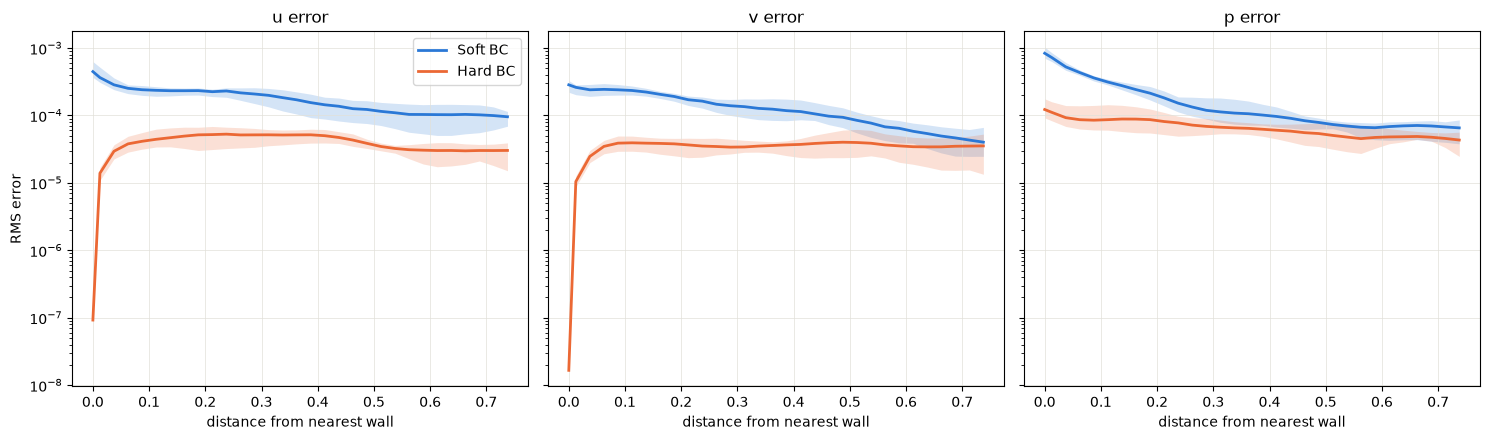

In [4]:
# NEW: RMS error vs distance from the nearest wall. Line = mean over the seeds, shading = lowest to highest seed.
edges = np.linspace(0, 0.75, 31)                                # 0.75 is the largest possible distance from a wall
bins = list(zip(edges[:-1], edges[1:]))
distance = np.concatenate([[0], (edges[:-1] + edges[1:]) / 2])  # distance 0 = the walls themselves

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for i, (ax, var) in enumerate(zip(axes, variables)):
    for name in methods:
        errors = np.array([[rms_error(run, i, "walls")] + [rms_error(run, i, b) for b in bins]
                           for run in runs[name]])               # shape (seeds, distances)
        ax.fill_between(distance, errors.min(axis=0), errors.max(axis=0), color=colors[name], alpha=0.2, linewidth=0)
        ax.plot(distance, errors.mean(axis=0), color=colors[name], linewidth=2, label=name)
    ax.set_yscale("log")
    ax.set_title(f"{var} error")
    ax.set_xlabel("distance from nearest wall")
    ax.grid(True, color="#e1e0d9", linewidth=0.5)
axes[0].set_ylabel("RMS error")
axes[0].legend()
plt.tight_layout()
plt.show()

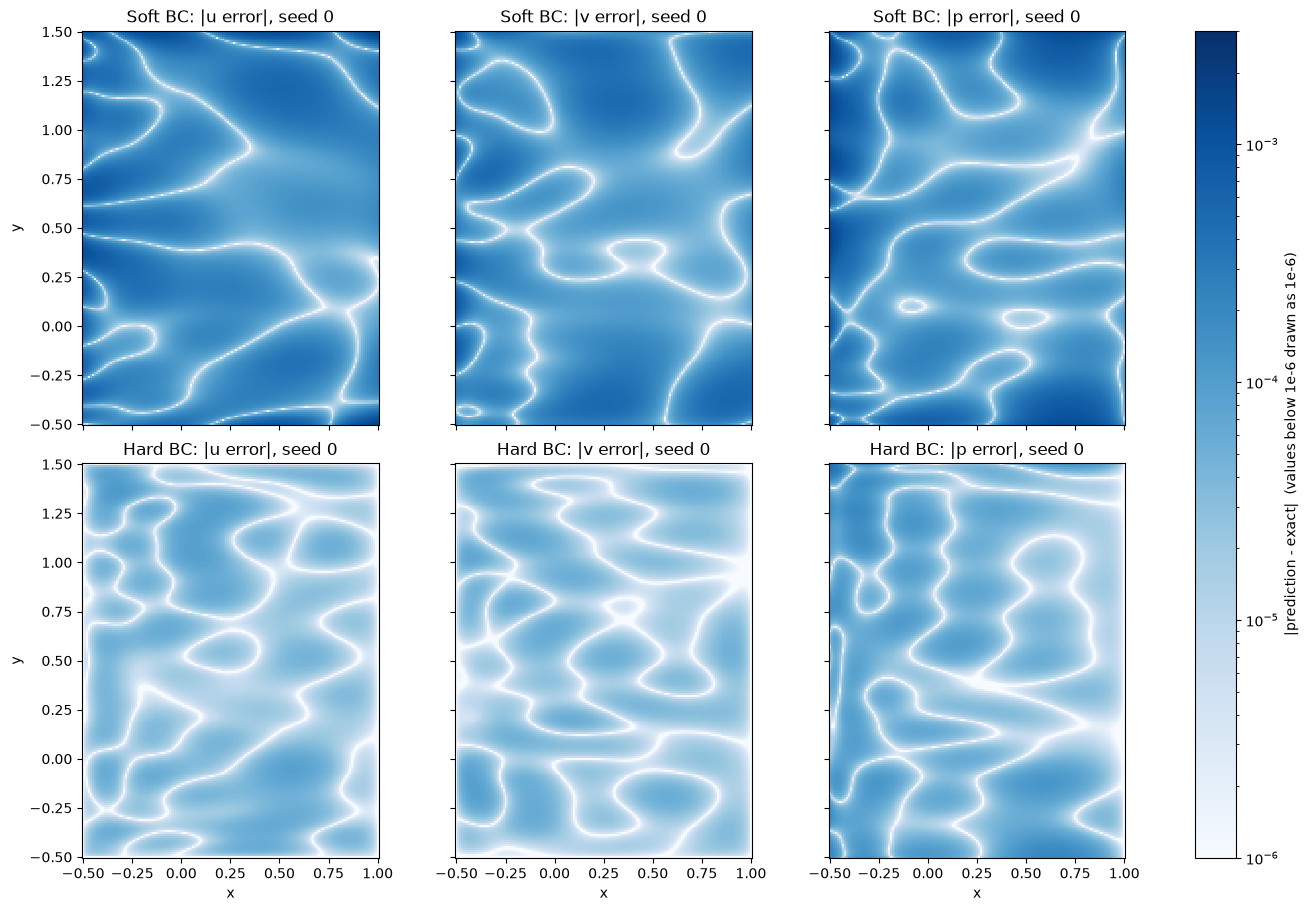

In [5]:
# NEW: where the error is. |prediction - exact| on the plotting grid for one seed, same color scale in every panel.
seed = 0
norm = LogNorm(vmin=1e-6, vmax=3e-3)

fig, axes = plt.subplots(2, 3, figsize=(13, 9), sharex=True, sharey=True, layout="constrained")
for row, name in enumerate(methods):
    run = runs[name][seed]
    for i, var in enumerate(variables):
        error = np.abs(run["grid_pred"][..., i] - run["grid_exact"][..., i])
        ax = axes[row, i]
        image = ax.pcolormesh(run["grid_x"], run["grid_y"], np.maximum(error, norm.vmin),
                              norm=norm, cmap="Blues", shading="auto")
        ax.set_title(f"{name}: |{var} error|, seed {seed}")
        ax.set_aspect("equal")
for ax in axes[1]:
    ax.set_xlabel("x")
for ax in axes[:, 0]:
    ax.set_ylabel("y")
fig.colorbar(image, ax=axes, label="|prediction - exact|  (values below 1e-6 drawn as 1e-6)")
plt.show()